In [ ]:
import pandas as pd
import numpy as np

# ==========================================
# GLOBAL DISPLAY SETTINGS
# ==========================================

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
df=pd.read_excel("FIFA2020_dataset.xlsx")
# ==========================================
# UNIVERSAL DATA QUALITY REPORT
# ==========================================

def generate_universal_report(dataframe):

    report_data = []

    for col in dataframe.columns:

        column_data = dataframe[col]

        # Safe sample value
        valid_data = column_data.dropna()

        if not valid_data.empty:
            sample_value = valid_data.iloc[0]
        else:
            sample_value = "ALL BLANK"

        # Detect numeric columns
        is_numeric = pd.api.types.is_numeric_dtype(column_data)

        # Numeric statistics
        if is_numeric:
            min_value = column_data.min()
            max_value = column_data.max()
            mean_value = round(column_data.mean(), 2)
            median_value = round(column_data.median(), 2)
        else:
            min_value = "N/A"
            max_value = "N/A"
            mean_value = "N/A"
            median_value = "N/A"

        report_data.append({
            'Column Name': col,
            'Data Type': str(column_data.dtype),
            'Total Missing': column_data.isnull().sum(),
            '% Missing': round(
                (column_data.isnull().sum() / len(dataframe)) * 100,
                2
            ),
            'Unique Values': column_data.nunique(),
            'Minimum': min_value,
            'Maximum': max_value,
            'Average': mean_value,
            'Median': median_value,
            'Sample Value': sample_value
        })

    report_df = pd.DataFrame(report_data)

    report_df = report_df.set_index('Column Name')

    return report_df

# ==========================================
# LOAD DATASET
# ==========================================

# Example:
# df = pd.read_csv('dataset.csv')
# df = pd.read_excel('dataset.xlsx')

# ==========================================
# EXECUTIVE SUMMARY
# ==========================================

print("=== UNIVERSAL DATASET SUMMARY ===")

print(f"Total Rows: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")
print(f"Total Duplicate Rows: {df.duplicated().sum()}")

print("-" * 50)

print("=== COMPLETE DATA QUALITY REPORT ===")

# ==========================================
# GENERATE REPORT
# ==========================================

final_report = generate_universal_report(df)
import pandas as pd
import numpy as np

# --- 1. FINANCIALS: Release Clause (Based on Median) ---
# We use the median to avoid bias from superstar outliers
median_val = df['release_clause_eur'].median()
df['release_clause_eur'] = df['release_clause_eur'].fillna(median_val)

# --- 2. TIME: Contract Leverge ---
# Convert expiration date into "years remaining" relative to 2026
current_year = 2026 
df['contract_valid_until'] = pd.to_numeric(df['contract_valid_until'], errors='coerce')
df['years_until_expiration'] = (df['contract_valid_until'] - current_year).clip(lower=0)
df['years_until_expiration'] = df['years_until_expiration'].fillna(0)

# --- 3. CATEGORICAL ENCODING: Foot & Work Rate ---
# Convert Preferred Foot to Binary (Left = 0, Right = 1)
df['preferred_foot_num'] = df['preferred_foot'].map({'Left': 0, 'Right': 1}).fillna(1)

# Split Work Rate (e.g., 'High/Medium') into two numeric columns
work_rate_map = {'Low': 1, 'Medium': 2, 'High': 3}

# We split the string and map the values to numbers
df['work_rate_att'] = df['work_rate'].str.split('/').str[0].map(work_rate_map).fillna(2)
df['work_rate_def'] = df['work_rate'].str.split('/').str[1].map(work_rate_map).fillna(2)

# --- 4. PURGE: Redundant & High-NaN Columns ---
# Dropping summary floats to focus on granular attribute ints (5s and 7s) for realism
cols_to_drop = [
    'joined', 'nation_position', 'contract_valid_until', 'preferred_foot', 'work_rate',
    'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic',
    'gk_diving', 'gk_handling', 'gk_kicking', 'gk_reflexes', 'gk_speed', 'gk_positioning'
]
df = df.drop(columns=cols_to_drop, errors='ignore')

# --- 5. FINAL CLEANUP & TYPE CHECK ---
# Catch any remaining NaNs in detailed skill columns and convert all to numeric
df = df.fillna(0)
df = df.apply(pd.to_numeric, errors='coerce')

print("🚀 CLEANING COMPLETE")
print(f"Final Column Count: {len(df.columns)}")
print(f"Any non-numeric columns left? {df.select_dtypes(include=['object']).columns.tolist()}")
display(final_report)

=== VISUALIZATION DASHBOARD STARTED ===



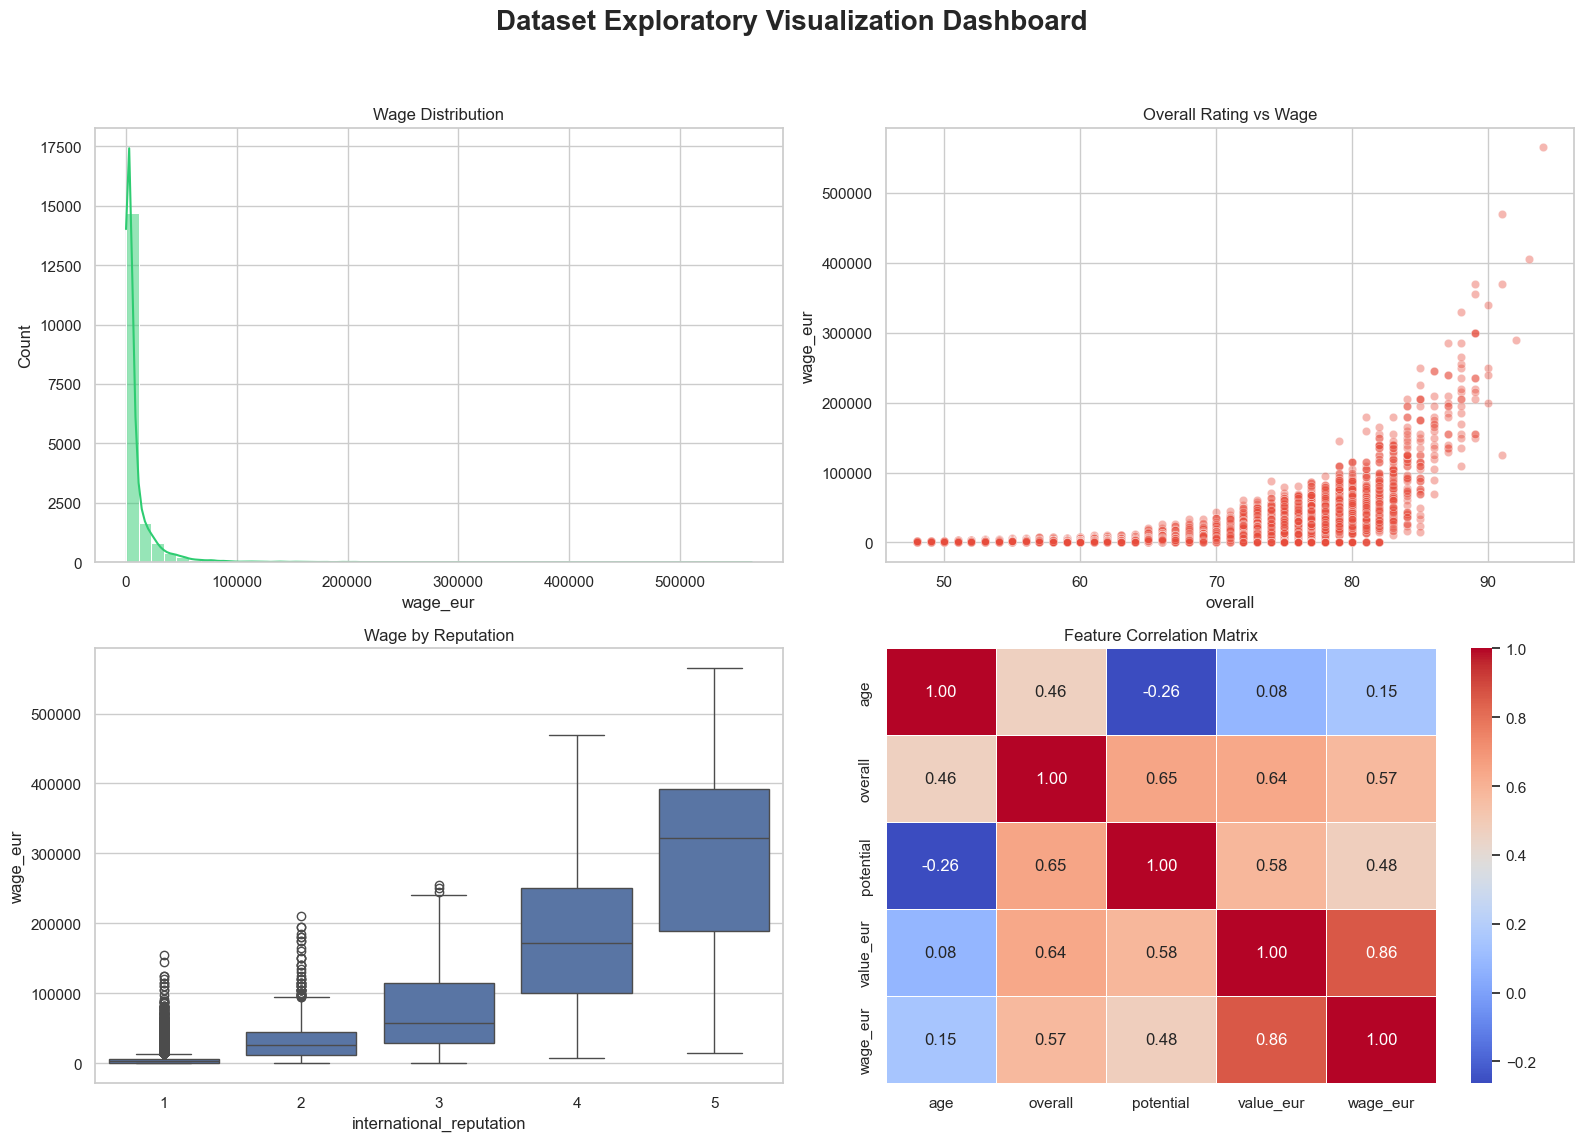


=== VISUALIZATION COMPLETE ===


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

print("=== VISUALIZATION DASHBOARD STARTED ===\n")

# ==================================================
# SAFETY CHECK (NO REPROCESSING, ONLY VALIDATION)
# ==================================================

required_cols = ['wage_eur', 'overall', 'international_reputation', 'age', 'potential', 'value_eur']

missing = [col for col in required_cols if col not in df.columns]

if missing:
    raise ValueError(f"Missing columns for visualization: {missing}")

# Use same dataset (NO df_clean creation to avoid duplication)
data = df

# ==================================================
# VISUAL STYLE CONFIG
# ==================================================

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

fig.suptitle(
    "Dataset Exploratory Visualization Dashboard",
    fontsize=20,
    fontweight='bold'
)

# ==================================================
# 1. DISTRIBUTION (WAGE)
# ==================================================

sns.histplot(
    data['wage_eur'],
    bins=50,
    kde=True,
    ax=axes[0, 0],
    color="#2ecc71"
)

axes[0, 0].set_title("Wage Distribution")
axes[0, 0].ticklabel_format(style='plain', axis='x')

# ==================================================
# 2. RELATIONSHIP (OVERALL vs WAGE)
# ==================================================

sns.scatterplot(
    data=data,
    x='overall',
    y='wage_eur',
    alpha=0.4,
    ax=axes[0, 1],
    color="#e74c3c"
)

axes[0, 1].set_title("Overall Rating vs Wage")
axes[0, 1].ticklabel_format(style='plain', axis='y')

# ==================================================
# 3. GROUP ANALYSIS (REPUTATION IMPACT)
# ==================================================

sns.boxplot(
    data=data,
    x='international_reputation',
    y='wage_eur',
    ax=axes[1, 0]
)

axes[1, 0].set_title("Wage by Reputation")
axes[1, 0].ticklabel_format(style='plain', axis='y')

# ==================================================
# 4. CORRELATION INSIGHT
# ==================================================

corr_cols = ['age', 'overall', 'potential', 'value_eur', 'wage_eur']

sns.heatmap(
    data[corr_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Feature Correlation Matrix")

# ==================================================
# FINAL LAYOUT OPTIMIZATION
# ==================================================

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

print("\n=== VISUALIZATION COMPLETE ===")

In [23]:
for col in df.columns:
    print(col, "-", df[col].dtype)

sofifa_id - int64
player_url - object
short_name - object
long_name - object
age - int64
dob - datetime64[ns]
height_cm - int64
weight_kg - int64
nationality - object
club - object
overall - int64
potential - int64
value_eur - int64
wage_eur - int64
player_positions - object
preferred_foot - object
international_reputation - int64
weak_foot - int64
skill_moves - int64
work_rate - object
body_type - object
real_face - object
release_clause_eur - float64
player_tags - object
team_position - object
team_jersey_number - float64
loaned_from - object
joined - datetime64[ns]
contract_valid_until - float64
nation_position - object
nation_jersey_number - float64
pace - float64
shooting - float64
passing - float64
dribbling - float64
defending - float64
physic - float64
gk_diving - float64
gk_handling - float64
gk_kicking - float64
gk_reflexes - float64
gk_speed - float64
gk_positioning - float64
player_traits - object
attacking_crossing - int64
attacking_finishing - int64
attacking_heading_accu

In [24]:
print("=== DROPPING IDENTITY COLUMNS ===\n")

# 1. The exact list of columns you want to drop
columns_to_drop = [
    'sofifa_id', 
    'player_url', 
    'short_name', 
    'long_name', 
    'dob'
]

# 2. Execute the drop and overwrite the dataset
df = df.drop(columns=columns_to_drop, errors='ignore')

# 3. Print the confirmation
print(f"Successfully dropped {len(columns_to_drop)} columns.")
print(f"Your dataset now has {df.shape[1]} columns remaining.")

=== DROPPING IDENTITY COLUMNS ===

Successfully dropped 5 columns.
Your dataset now has 99 columns remaining.


In [25]:
df.head()

,age,height_cm,weight_kg,nationality,club,overall,potential,value_eur,wage_eur,player_positions,preferred_foot,international_reputation,weak_foot,skill_moves,work_rate,body_type,real_face,release_clause_eur,player_tags,team_position,team_jersey_number,loaned_from,joined,contract_valid_until,nation_position,nation_jersey_number,pace,shooting,passing,dribbling,defending,physic,gk_diving,gk_handling,gk_kicking,gk_reflexes,gk_speed,gk_positioning,player_traits,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,skill_curve,skill_fk_accuracy,skill_long_passing,skill_ball_control,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,ls,st,rs,lw,lf,cf,rf,rw,lam,cam,ram,lm,lcm,cm,rcm,rm,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb
0,32,170,72,Argentina,FC Barcelona,94,94,95500000,565000,"RW, CF, ST",Left,5,4,4,Medium/Low,Messi,Yes,195800000.0,"#Dribbler, #Distance Shooter, #Crosser, #FK Sp...",RW,10.0,NaN,2004-07-01,2021.0,NaN,NaN,87.0,92.0,92.0,96.0,39.0,66.0,NaN,NaN,NaN,NaN,NaN,NaN,"Beat Offside Trap, Argues with Officials, Earl...",88,95,70,92,88,97,93,94,92,96,91,84,93,95,95,86,68,75,68,94,48,40,94,94,75,96,33,37,26,6,11,15,14,8,89+2,89+2,89+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,92+2,87+2,87+2,87+2,92+2,68+2,66+2,66+2,66+2,68+2,63+2,52+2,52+2,52+2,63+2
1,34,187,83,Portugal,Juventus,93,93,58500000,405000,"ST, LW",Right,5,4,5,High/Low,C. Ronaldo,Yes,96500000.0,"#Speedster, #Dribbler, #Distance Shooter, #Acr...",LW,7.0,NaN,2018-07-10,2022.0,LS,7.0,90.0,93.0,82.0,89.0,35.0,78.0,NaN,NaN,NaN,NaN,NaN,NaN,"Long Throw-in, Selfish, Argues with Officials,...",84,94,89,83,87,89,81,76,77,92,89,91,87,96,71,95,95,85,78,93,63,29,95,82,85,95,28,32,24,7,11,15,14,11,91+3,91+3,91+3,89+3,90+3,90+3,90+3,89+3,88+3,88+3,88+3,88+3,81+3,81+3,81+3,88+3,65+3,61+3,61+3,61+3,65+3,61+3,53+3,53+3,53+3,61+3
2,27,175,68,Brazil,Paris Saint-Germain,92,92,105500000,290000,"LW, CAM",Right,5,5,5,High/Medium,Neymar,Yes,195200000.0,"#Speedster, #Dribbler, #PlaymakerÂ , #Crosser...",CAM,10.0,NaN,2017-08-03,2022.0,LW,10.0,91.0,85.0,87.0,95.0,32.0,58.0,NaN,NaN,NaN,NaN,NaN,NaN,"Power Free-Kick, Injury Free, Selfish, Early C...",87,87,62,87,87,96,88,87,81,95,94,89,96,92,84,80,61,81,49,84,51,36,87,90,90,94,27,26,29,9,9,15,15,11,84+3,84+3,84+3,90+3,89+3,89+3,89+3,90+3,90+3,90+3,90+3,89+3,82+3,82+3,82+3,89+3,66+3,61+3,61+3,61+3,66+3,61+3,46+3,46+3,46+3,61+3
3,26,188,87,Slovenia,AtlÃ©tico Madrid,91,93,77500000,125000,GK,Right,3,3,1,Medium/Medium,Normal,Yes,164700000.0,NaN,GK,13.0,NaN,2014-07-16,2023.0,GK,1.0,NaN,NaN,NaN,NaN,NaN,NaN,87.0,92.0,78.0,89.0,52.0,90.0,"Flair, Acrobatic Clearance",13,11,15,43,13,12,13,14,40,30,43,60,67,88,49,59,78,41,78,12,34,19,11,65,11,68,27,12,18,87,92,78,90,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,28,175,74,Belgium,Real Madrid,91,91,90000000,470000,"LW, CF",Right,4,4,4,High/Medium,Normal,Yes,184500000.0,"#Speedster, #Dribbler, #Acrobat",LW,7.0,NaN,2019-07-01,2024.0,LF,10.0,91.0,83.0,86.0,94.0,35.0,66.0,NaN,NaN,NaN,NaN,NaN,NaN,"Beat Offside Trap, Selfish, Finesse Shot, Spee...",81,84,61,89,83,95,83,79,83,94,94,88,95,90,94,82,56,84,63,80,54,41,87,89,88,91,34,27,22,11,12,6,8,8,83+3,83+3,83+3,89+3,88+3,88+3,88+3,89+3,89+3,89+3,89+3,89+3,83+3,83+3,83+3,89+3,66+3,63+3,63+3,63+3,66+3,61+3,49+3,49+3,49+3,61+3


In [26]:
# 1. Get a simple list of all unique nationalities
distinct_nationalities = df['nationality'].unique()

# 2. Sort them alphabetically so they are easier to read
distinct_nationalities.sort()

print(f"Total distinct nationalities found: {len(distinct_nationalities)}")
print("-" * 30)
print(distinct_nationalities)

Total distinct nationalities found: 162
------------------------------
['Afghanistan' 'Albania' 'Algeria' 'Angola' 'Antigua & Barbuda'
 'Argentina' 'Armenia' 'Australia' 'Austria' 'Azerbaijan' 'Bahrain'
 'Barbados' 'Belgium' 'Belize' 'Benin' 'Bermuda' 'Bolivia'
 'Bosnia Herzegovina' 'Brazil' 'Bulgaria' 'Burkina Faso' 'Burundi'
 'Cameroon' 'Canada' 'Cape Verde' 'Central African Rep.' 'Chad' 'Chile'
 'China PR' 'Chinese Taipei' 'Colombia' 'Comoros' 'Congo' 'Costa Rica'
 'Croatia' 'Cuba' 'Curacao' 'Cyprus' 'Czech Republic' 'DR Congo' 'Denmark'
 'Dominican Republic' 'Ecuador' 'Egypt' 'El Salvador' 'England'
 'Equatorial Guinea' 'Eritrea' 'Estonia' 'Ethiopia' 'FYR Macedonia'
 'Faroe Islands' 'Finland' 'France' 'Gabon' 'Gambia' 'Georgia' 'Germany'
 'Ghana' 'Gibraltar' 'Greece' 'Grenada' 'Guam' 'Guatemala' 'Guinea'
 'Guinea Bissau' 'Guyana' 'Haiti' 'Honduras' 'Hong Kong' 'Hungary'
 'Iceland' 'India' 'Indonesia' 'Iran' 'Iraq' 'Israel' 'Italy'
 'Ivory Coast' 'Jamaica' 'Japan' 'Jordan' 'Kazakhst

In [27]:
import pandas as pd

print("=== STEP: NATIONALITY DIMENSIONALITY REDUCTION ===\n")

# 1. Identify the Top 10 most frequent nationalities
# This ensures we keep the most "statistically significant" countries
top_10_nations = df['nationality'].value_counts().nlargest(10).index.tolist()

print(f"Top 10 Nationalities being kept: {top_10_nations}")

# 2. Apply the 'Other' logic
# If a player's nationality is NOT in the top 10, rename it to 'Other'
df['nationality_mapped'] = df['nationality'].apply(lambda x: x if x in top_10_nations else 'Other')

# 3. Verify the new distribution
print("\nNew Grouped Distribution:")
print(df['nationality_mapped'].value_counts())

# 4. Convert to Binary Columns (One-Hot Encoding)
# This creates 11 columns (Top 10 + Other) filled with 0s and 1s
df = pd.get_dummies(df, columns=['nationality_mapped'], prefix='nat', dtype=int)

# 5. Drop the original text column so the model only sees numbers
df = df.drop(columns=['nationality'])

print("\nNationality Encoding Complete. Original column dropped.")
print(f"New columns added: {[col for col in df.columns if col.startswith('nat_')]}")

=== STEP: NATIONALITY DIMENSIONALITY REDUCTION ===

Top 10 Nationalities being kept: ['England', 'Germany', 'Spain', 'France', 'Argentina', 'Brazil', 'Italy', 'Colombia', 'Japan', 'Netherlands']

New Grouped Distribution:
nationality_mapped
Other          9474
England        1667
Germany        1216
Spain          1035
France          984
Argentina       886
Brazil          824
Italy           732
Colombia        591
Japan           453
Netherlands     416
Name: count, dtype: int64

Nationality Encoding Complete. Original column dropped.
New columns added: ['nat_Argentina', 'nat_Brazil', 'nat_Colombia', 'nat_England', 'nat_France', 'nat_Germany', 'nat_Italy', 'nat_Japan', 'nat_Netherlands', 'nat_Other', 'nat_Spain']


In [28]:
df.head()

,age,height_cm,weight_kg,club,overall,potential,value_eur,wage_eur,player_positions,preferred_foot,international_reputation,weak_foot,skill_moves,work_rate,body_type,real_face,release_clause_eur,player_tags,team_position,team_jersey_number,loaned_from,joined,contract_valid_until,nation_position,nation_jersey_number,pace,shooting,passing,dribbling,defending,physic,gk_diving,gk_handling,gk_kicking,gk_reflexes,gk_speed,gk_positioning,player_traits,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,skill_curve,skill_fk_accuracy,skill_long_passing,skill_ball_control,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,ls,st,rs,lw,lf,cf,rf,rw,lam,cam,ram,lm,lcm,cm,rcm,rm,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb,nat_Argentina,nat_Brazil,nat_Colombia,nat_England,nat_France,nat_Germany,nat_Italy,nat_Japan,nat_Netherlands,nat_Other,nat_Spain
0,32,170,72,FC Barcelona,94,94,95500000,565000,"RW, CF, ST",Left,5,4,4,Medium/Low,Messi,Yes,195800000.0,"#Dribbler, #Distance Shooter, #Crosser, #FK Sp...",RW,10.0,NaN,2004-07-01,2021.0,NaN,NaN,87.0,92.0,92.0,96.0,39.0,66.0,NaN,NaN,NaN,NaN,NaN,NaN,"Beat Offside Trap, Argues with Officials, Earl...",88,95,70,92,88,97,93,94,92,96,91,84,93,95,95,86,68,75,68,94,48,40,94,94,75,96,33,37,26,6,11,15,14,8,89+2,89+2,89+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,92+2,87+2,87+2,87+2,92+2,68+2,66+2,66+2,66+2,68+2,63+2,52+2,52+2,52+2,63+2,1,0,0,0,0,0,0,0,0,0,0
1,34,187,83,Juventus,93,93,58500000,405000,"ST, LW",Right,5,4,5,High/Low,C. Ronaldo,Yes,96500000.0,"#Speedster, #Dribbler, #Distance Shooter, #Acr...",LW,7.0,NaN,2018-07-10,2022.0,LS,7.0,90.0,93.0,82.0,89.0,35.0,78.0,NaN,NaN,NaN,NaN,NaN,NaN,"Long Throw-in, Selfish, Argues with Officials,...",84,94,89,83,87,89,81,76,77,92,89,91,87,96,71,95,95,85,78,93,63,29,95,82,85,95,28,32,24,7,11,15,14,11,91+3,91+3,91+3,89+3,90+3,90+3,90+3,89+3,88+3,88+3,88+3,88+3,81+3,81+3,81+3,88+3,65+3,61+3,61+3,61+3,65+3,61+3,53+3,53+3,53+3,61+3,0,0,0,0,0,0,0,0,0,1,0
2,27,175,68,Paris Saint-Germain,92,92,105500000,290000,"LW, CAM",Right,5,5,5,High/Medium,Neymar,Yes,195200000.0,"#Speedster, #Dribbler, #PlaymakerÂ , #Crosser...",CAM,10.0,NaN,2017-08-03,2022.0,LW,10.0,91.0,85.0,87.0,95.0,32.0,58.0,NaN,NaN,NaN,NaN,NaN,NaN,"Power Free-Kick, Injury Free, Selfish, Early C...",87,87,62,87,87,96,88,87,81,95,94,89,96,92,84,80,61,81,49,84,51,36,87,90,90,94,27,26,29,9,9,15,15,11,84+3,84+3,84+3,90+3,89+3,89+3,89+3,90+3,90+3,90+3,90+3,89+3,82+3,82+3,82+3,89+3,66+3,61+3,61+3,61+3,66+3,61+3,46+3,46+3,46+3,61+3,0,1,0,0,0,0,0,0,0,0,0
3,26,188,87,AtlÃ©tico Madrid,91,93,77500000,125000,GK,Right,3,3,1,Medium/Medium,Normal,Yes,164700000.0,NaN,GK,13.0,NaN,2014-07-16,2023.0,GK,1.0,NaN,NaN,NaN,NaN,NaN,NaN,87.0,92.0,78.0,89.0,52.0,90.0,"Flair, Acrobatic Clearance",13,11,15,43,13,12,13,14,40,30,43,60,67,88,49,59,78,41,78,12,34,19,11,65,11,68,27,12,18,87,92,78,90,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,0,0,0,0,1,0
4,28,175,74,Real Madrid,91,91,90000000,470000,"LW, CF",Right,4,4,4,High/Medium,Normal,Yes,184500000.0,"#Speedster, #Dribbler, #Acrobat",LW,7.0,NaN,2019-07-01,2024.0,LF,10.0,91.0,83.0,86.0,94.0,35.0,66.0,NaN,NaN,NaN,NaN,NaN,NaN,"Beat Offside Trap, Selfish, Finesse Shot, Spee...",81,84,61,89,83,95,83,79,83,94,94,88,95,90,94,82,56,84,63,80,54,41,87,89,88,91,34,27,22,11,12,6,8,8,83+3,83+3,83+3,89+3,88+3,88+3,88+3,89+3,89+3,89+3,89+3,89+3,83+3,83+3,83+3,89+3,66+3,63+3,63+3,63+3,66+3,61+3,49+3,49+3,49+3,61+3,0,0,0,0,0,0,0,0,0,1,0


In [29]:
print(df["club"].unique())

['FC Barcelona' 'Juventus' 'Paris Saint-Germain' 'AtlÃ©tico Madrid'
 'Real Madrid' 'Manchester City' 'Liverpool' 'Napoli' 'Tottenham Hotspur'
 'Manchester United' 'Chelsea' 'FC Bayern MÃ¼nchen' 'Inter'
 'Borussia Dortmund' 'Arsenal' 'Valencia CF' 'Lazio' 'Milan' 'Sporting CP'
 'Olympique Lyonnais' 'RB Leipzig' 'Ajax' 'LA Galaxy' 'Atalanta'
 'RC Celta' 'Bayer 04 Leverkusen' 'Real Betis' 'FC Porto'
 'SV Werder Bremen' 'West Ham United' 'Wolverhampton Wanderers'
 'AS Saint-Ã‰tienne' 'Torino' 'Dalian YiFang FC'
 'Borussia MÃ¶nchengladbach' 'Roma' 'Guangzhou Evergrande Taobao FC'
 'SL Benfica' 'Medipol BaÅŸakÅŸehir FK' 'Everton' 'VfL Wolfsburg'
 'Crystal Palace' 'Getafe CF' 'Shanghai SIPG FC' 'Eintracht Frankfurt'
 'Olympique de Marseille' 'Hertha BSC' 'RSC Anderlecht' 'Villarreal CF'
 'Sampdoria' 'Leicester City' 'AS Monaco' 'Jiangsu Suning FC'
 'Los Angeles FC' 'Cagliari' 'Sevilla FC' 'FenerbahÃ§e SK' 'Real Sociedad'
 'TSG 1899 Hoffenheim' 'AtlÃ©tico Mineiro' 'GrÃªmio' 'PSV'
 'Athletic Cl

In [30]:
import pandas as pd

print("=== STRATEGIC CLUB GROUPING (MARKET VALUE 2026) ===\n")

# 1. Define the Elite 15 based on global valuation rankings
# I have matched these to the exact spelling in your provided list
elite_15_clubs = [
    'Real Madrid', 'FC Barcelona', 'Manchester United', 'Liverpool', 
    'Manchester City', 'FC Bayern MÃ¼nchen', 'Paris Saint-Germain', 'Arsenal', 
    'Tottenham Hotspur', 'Chelsea', 'Inter', 'Borussia Dortmund', 
    'AtlÃ©tico Madrid', 'Milan', 'Juventus'
]

# 2. Map the clubs
# This creates a new column: If club is in our list, keep it. Else, 'Other_Clubs'
df['club_category'] = df['club'].apply(lambda x: x if x in elite_15_clubs else 'Other_Clubs')

# 3. Create Binary Integer Columns (One-Hot Encoding)
# This results in 16 columns (15 Elite + 1 Other) filled with 1s and 0s
df = pd.get_dummies(df, columns=['club_category'], prefix='is', dtype=int)

# 4. Drop the original messy club column
df = df.drop(columns=['club'], errors='ignore')

print(f"Strategic Grouping complete. {len(elite_15_clubs)} Elite columns created.")
print(f"Total columns in dataset now: {df.shape[1]}")

=== STRATEGIC CLUB GROUPING (MARKET VALUE 2026) ===

Strategic Grouping complete. 15 Elite columns created.
Total columns in dataset now: 124


In [31]:
import pandas as pd

print("=== STEP: PLAYER POSITION GROUPING ===\n")

# 1. Define the mapping dictionary
pos_map = {
    'ST': 'Attack', 'CF': 'Attack', 'RW': 'Attack', 'LW': 'Attack', 'RF': 'Attack', 'LF': 'Attack',
    'CAM': 'Midfield', 'RAM': 'Midfield', 'LAM': 'Midfield', 'CM': 'Midfield', 'RCM': 'Midfield', 'LCM': 'Midfield',
    'CDM': 'Midfield', 'RDM': 'Midfield', 'LDM': 'Midfield', 'RM': 'Midfield', 'LM': 'Midfield',
    'CB': 'Defense', 'RCB': 'Defense', 'LCB': 'Defense', 'RB': 'Defense', 'LB': 'Defense', 'RWB': 'Defense', 'LWB': 'Defense',
    'GK': 'Goalkeeper'
}

# 2. Since some players have multiple positions (e.g., "ST, RW"), 
# we will take their FIRST (primary) position listed.
df['primary_position'] = df['player_positions'].str.split(',').str[0]

# 3. Map the primary position to our 4 main categories
df['role'] = df['primary_position'].map(pos_map)

# 4. Fill any missing values with 'Midfield' (the most common) just in case
df['role'] = df['role'].fillna('Midfield')

# 5. One-Hot Encode the roles (Creates 'role_Attack', 'role_Defense', etc.)
df = pd.get_dummies(df, columns=['role'], prefix='role', dtype=int)

# 6. Drop the original messy text columns
df = df.drop(columns=['player_positions', 'primary_position'], errors='ignore')

print("Position Grouping Complete!")
print(f"New Columns Created: {[col for col in df.columns if col.startswith('role_')]}")

=== STEP: PLAYER POSITION GROUPING ===

Position Grouping Complete!
New Columns Created: ['role_Attack', 'role_Defense', 'role_Goalkeeper', 'role_Midfield']


In [32]:
df.head()

,age,height_cm,weight_kg,overall,potential,value_eur,wage_eur,preferred_foot,international_reputation,weak_foot,skill_moves,work_rate,body_type,real_face,release_clause_eur,player_tags,team_position,team_jersey_number,loaned_from,joined,contract_valid_until,nation_position,nation_jersey_number,pace,shooting,passing,dribbling,defending,physic,gk_diving,gk_handling,gk_kicking,gk_reflexes,gk_speed,gk_positioning,player_traits,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,skill_curve,skill_fk_accuracy,skill_long_passing,skill_ball_control,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,ls,st,rs,lw,lf,cf,rf,rw,lam,cam,ram,lm,lcm,cm,rcm,rm,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb,nat_Argentina,nat_Brazil,nat_Colombia,nat_England,nat_France,nat_Germany,nat_Italy,nat_Japan,nat_Netherlands,nat_Other,nat_Spain,is_Arsenal,is_AtlÃ©tico Madrid,is_Borussia Dortmund,is_Chelsea,is_FC Barcelona,is_FC Bayern MÃ¼nchen,is_Inter,is_Juventus,is_Liverpool,is_Manchester City,is_Manchester United,is_Milan,is_Other_Clubs,is_Paris Saint-Germain,is_Real Madrid,is_Tottenham Hotspur,role_Attack,role_Defense,role_Goalkeeper,role_Midfield
0,32,170,72,94,94,95500000,565000,Left,5,4,4,Medium/Low,Messi,Yes,195800000.0,"#Dribbler, #Distance Shooter, #Crosser, #FK Sp...",RW,10.0,NaN,2004-07-01,2021.0,NaN,NaN,87.0,92.0,92.0,96.0,39.0,66.0,NaN,NaN,NaN,NaN,NaN,NaN,"Beat Offside Trap, Argues with Officials, Earl...",88,95,70,92,88,97,93,94,92,96,91,84,93,95,95,86,68,75,68,94,48,40,94,94,75,96,33,37,26,6,11,15,14,8,89+2,89+2,89+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,92+2,87+2,87+2,87+2,92+2,68+2,66+2,66+2,66+2,68+2,63+2,52+2,52+2,52+2,63+2,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
1,34,187,83,93,93,58500000,405000,Right,5,4,5,High/Low,C. Ronaldo,Yes,96500000.0,"#Speedster, #Dribbler, #Distance Shooter, #Acr...",LW,7.0,NaN,2018-07-10,2022.0,LS,7.0,90.0,93.0,82.0,89.0,35.0,78.0,NaN,NaN,NaN,NaN,NaN,NaN,"Long Throw-in, Selfish, Argues with Officials,...",84,94,89,83,87,89,81,76,77,92,89,91,87,96,71,95,95,85,78,93,63,29,95,82,85,95,28,32,24,7,11,15,14,11,91+3,91+3,91+3,89+3,90+3,90+3,90+3,89+3,88+3,88+3,88+3,88+3,81+3,81+3,81+3,88+3,65+3,61+3,61+3,61+3,65+3,61+3,53+3,53+3,53+3,61+3,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0
2,27,175,68,92,92,105500000,290000,Right,5,5,5,High/Medium,Neymar,Yes,195200000.0,"#Speedster, #Dribbler, #PlaymakerÂ , #Crosser...",CAM,10.0,NaN,2017-08-03,2022.0,LW,10.0,91.0,85.0,87.0,95.0,32.0,58.0,NaN,NaN,NaN,NaN,NaN,NaN,"Power Free-Kick, Injury Free, Selfish, Early C...",87,87,62,87,87,96,88,87,81,95,94,89,96,92,84,80,61,81,49,84,51,36,87,90,90,94,27,26,29,9,9,15,15,11,84+3,84+3,84+3,90+3,89+3,89+3,89+3,90+3,90+3,90+3,90+3,89+3,82+3,82+3,82+3,89+3,66+3,61+3,61+3,61+3,66+3,61+3,46+3,46+3,46+3,61+3,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
3,26,188,87,91,93,77500000,125000,Right,3,3,1,Medium/Medium,Normal,Yes,164700000.0,NaN,GK,13.0,NaN,2014-07-16,2023.0,GK,1.0,NaN,NaN,NaN,NaN,NaN,NaN,87.0,92.0,78.0,89.0,52.0,90.0,"Flair, Acrobatic Clearance",13,11,15,43,13,12,13,14,40,30,43,60,67,88,49,59,78,41,78,12,34,19,11,65,11,68,27,12,18,87,92,78,90,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
4,28,175,74,91,91,90000000,470000,Right,4,4,4,High/Medium,Normal,Yes,184500000.0,"#Speedster, #Dribbler, #Acrobat",LW,7.0,NaN,2019-07-01,2024.0,LF,10.0,91.0,83.0,86.0,94.0,35.0,66.0,NaN,NaN,NaN,NaN,

In [33]:
print(df["player_traits"].unique())
null_count = df['player_traits'].isnull().sum()

print(f"Total null values in 'release_clause_eur': {null_count}")

['Beat Offside Trap, Argues with Officials, Early Crosser, Finesse Shot, Speed Dribbler (CPU AI Only), 1-on-1 Rush, Giant Throw-in, Outside Foot Shot'
 'Long Throw-in, Selfish, Argues with Officials, Early Crosser, Speed Dribbler (CPU AI Only), Skilled Dribbling'
 'Power Free-Kick, Injury Free, Selfish, Early Crosser, Speed Dribbler (CPU AI Only), Crowd Favourite'
 'Flair, Acrobatic Clearance'
 'Beat Offside Trap, Selfish, Finesse Shot, Speed Dribbler (CPU AI Only), Crowd Favourite'
 'Power Free-Kick, Avoids Using Weaker Foot, Dives Into Tackles (CPU AI Only), Leadership, Argues with Officials, Finesse Shot'
 'Swerve Pass, Acrobatic Clearance, Flair Passes'
 'Diver, Avoids Using Weaker Foot, Leadership, Long Passer (CPU AI Only)'
 'Argues with Officials, Finesse Shot, Speed Dribbler (CPU AI Only), Crowd Favourite'
 'Beat Offside Trap, Argues with Officials, Early Crosser, Speed Dribbler (CPU AI Only), Outside Foot Shot'
 'Beat Offside Trap, Selfish, Early Crosser, Speed Dribbler (CPU A

In [34]:
# Dropping nation_position due to high percentage of missing values and redundancy
df = df.drop(columns=['nation_jersey_number'], errors='ignore')

print("Column 'nation_jersey_number' dropped successfully.")

Column 'nation_jersey_number' dropped successfully.


In [35]:
# 1. Define the 'Bad' keywords specifically found in your list
bad_list = [
    'Argues with Officials', 'Selfish', 'Diver', 'Injury Prone', 
    'Inflexible', 'Dives Into Tackles'
]

def analyze_traits(trait_text):
    # Handle the 'nan' values you mentioned
    if pd.isna(trait_text) or trait_text == 'nan':
        return 0, 0
    
    # Split the string into individual traits
    traits = [t.strip() for t in trait_text.split(',')]
    
    # Count how many match our 'Bad' list
    bad_count = sum(1 for t in traits if t in bad_list)
    
    # Everything else is considered a 'Good' trait
    good_count = len(traits) - bad_count
    
    return good_count, bad_count

# 2. Apply the function to the DataFrame
df[['good_traits_count', 'bad_traits_count']] = df['player_traits'].apply(
    lambda x: pd.Series(analyze_traits(x))
)

# 3. Drop the original column to clean up
df = df.drop(columns=['player_traits'])

print("Trait analysis complete. Check your new columns:")
print(df[['good_traits_count', 'bad_traits_count']].head())

Trait analysis complete. Check your new columns:
   good_traits_count  bad_traits_count
0                  7                 1
1                  4                 2
2                  5                 1
3                  2                 0
4                  4                 1


In [36]:
# List of skill and attribute columns
skill_columns = [
    'shooting', 'passing', 'dribbling', 'defending', 'physic', 
    'gk_diving', 'gk_handling', 'gk_kicking', 'gk_reflexes', 'gk_speed', 'gk_positioning',
    'attacking_crossing', 'attacking_finishing', 'attacking_heading_accuracy', 
    'attacking_short_passing', 'attacking_volleys', 'skill_dribbling', 'skill_curve',
    'skill_fk_accuracy', 'skill_long_passing', 'skill_ball_control', 
    'movement_acceleration', 'movement_sprint_speed', 'movement_agility', 
    'movement_reactions', 'movement_balance', 'power_shot_power', 'power_jumping', 
    'power_stamina', 'power_strength', 'power_long_shots', 'mentality_aggression', 
    'mentality_interceptions', 'mentality_positioning', 'mentality_vision', 
    'mentality_penalties', 'mentality_composure', 'defending_marking', 
    'defending_standing_tackle', 'defending_sliding_tackle', 'goalkeeping_diving', 
    'goalkeeping_handling', 'goalkeeping_kicking', 'goalkeeping_positioning', 
    'goalkeeping_reflexes'
]

# Check for null values specifically in these columns
null_summary = df[skill_columns].isnull().sum()

# Filter and print only columns that actually have nulls
print("--- Null Values Count ---")
print(null_summary[null_summary > 0])

--- Null Values Count ---
shooting           2036
passing            2036
dribbling          2036
defending          2036
physic             2036
gk_diving         16242
gk_handling       16242
gk_kicking        16242
gk_reflexes       16242
gk_speed          16242
gk_positioning    16242
dtype: int64


In [37]:
# List of the columns you just verified have nulls
skill_columns = [
    'shooting', 'passing', 'dribbling', 'defending', 'physic', 
    'gk_diving', 'gk_handling', 'gk_kicking', 'gk_reflexes', 'gk_speed', 'gk_positioning'
]

# Fill all NaNs with 0
df[skill_columns] = df[skill_columns].fillna(0)

# Final verification to be 100% sure
remaining_nulls = df[skill_columns].isnull().sum().sum()
if remaining_nulls == 0:
    print("✅ Success! All skill nulls replaced with 0. Data is now airtight.")
else:
    print(f"⚠️ Warning: {remaining_nulls} nulls still remain.")

✅ Success! All skill nulls replaced with 0. Data is now airtight.


In [38]:
import datetime

# 1. Get the current year (2026)
current_year = 2020

# 2. Convert the column to numeric (it might be a string or float)
df['contract_valid_until'] = pd.to_numeric(df['contract_valid_until'], errors='coerce')

# 3. Create 'years_left' and fill missing values with 0 (assuming contract is ending)
df['years_until_expiration'] = (df['contract_valid_until'] - current_year).clip(lower=0)
df['years_until_expiration'] = df['years_until_expiration'].fillna(0)

# 4. Drop the original column
df = df.drop(columns=['contract_valid_until'], errors='ignore')

print("Converted contract dates into a 'Years Remaining' numeric feature.")

Converted contract dates into a 'Years Remaining' numeric feature.


In [39]:
print("=== STEP: PREFERRED FOOT BINARY ENCODING ===\n")

# 1. Create a simple dictionary for the mapping
# Most players are right-footed, so we often set Right to 1
foot_mapping = {'Right': 1, 'Left': 0}

# 2. Apply the mapping to the column
df['preferred_foot'] = df['preferred_foot'].map(foot_mapping)

# 3. Fill any unexpected missing values with 1 (Right foot is the statistical mode)
df['preferred_foot'] = df['preferred_foot'].fillna(1).astype(int)

print("Encoding Complete!")
print(f"Unique values now in 'preferred_foot': {df['preferred_foot'].unique()}")
print(df['preferred_foot'].value_counts())

=== STEP: PREFERRED FOOT BINARY ENCODING ===

Encoding Complete!
Unique values now in 'preferred_foot': [0 1]
preferred_foot
1    13960
0     4318
Name: count, dtype: int64


In [40]:
print("=== STEP: WORK RATE ORDINAL ENCODING ===\n")

# 1. Define the numeric mapping
rate_map = {'High': 3, 'Medium': 2, 'Low': 1}

# 2. Split the 'work_rate' column into two parts (Attacking / Defensive)
# Example: 'High/Low' becomes Attacking: 'High' and Defensive: 'Low'
df[['work_rate_attack', 'work_rate_defense']] = df['work_rate'].str.split('/', expand=True)

# 3. Map the text values to our numbers (1, 2, 3)
df['work_rate_attack'] = df['work_rate_attack'].map(rate_map)
df['work_rate_defense'] = df['work_rate_defense'].map(rate_map)

# 4. Drop the original messy text column
df = df.drop(columns=['work_rate'], errors='ignore')

print("Work Rate Encoding Complete!")
print(f"Attacking Work Rate values: {df['work_rate_attack'].unique()}")
print(f"Defensive Work Rate values: {df['work_rate_defense'].unique()}")

=== STEP: WORK RATE ORDINAL ENCODING ===

Work Rate Encoding Complete!
Attacking Work Rate values: [2 3 1]
Defensive Work Rate values: [1 2 3]


In [41]:
print("=== STEP: BODY TYPE ORDINAL ENCODING (SINGLE COLUMN) ===\n")

# 1. Create a dictionary to map every possibility to a number (1-3)
# We map specific players and codes directly to their numeric score
# 3 = Stocky (Strongest), 2 = Normal, 1 = Lean
body_ordinal_map = {
    'Lean': 1, 'Neymar': 1, 'Messi': 1,
    'Normal': 2, 'Courtois': 2, 'Shaqiri': 2, 'PLAYER_BODY_TYPE_25': 2,
    'Stocky': 3, 'C. Ronaldo': 3, 'Akinfenwa': 3
}

# 2. Apply the mapping to a new column
# Any values not in our list will default to 2 (Normal)
df['body_type_num'] = df['body_type'].map(body_ordinal_map).fillna(2).astype(int)

# 3. Drop the original string column
df = df.drop(columns=['body_type'], errors='ignore')

print("Success! Body Type is now a single numeric column.")
print(f"Unique values in body_type_num: {df['body_type_num'].unique()}")
print("-" * 30)
print(df['body_type_num'].value_counts())

=== STEP: BODY TYPE ORDINAL ENCODING (SINGLE COLUMN) ===

Success! Body Type is now a single numeric column.
Unique values in body_type_num: [1 3 2]
------------------------------
body_type_num
2    10753
1     6507
3     1018
Name: count, dtype: int64


In [42]:
# Drop the real_face column as it has no impact on player performance or wages
df = df.drop(columns=['real_face'], errors='ignore')

print("Column 'real_face' successfully dropped.")
print(f"Remaining columns in your dataset: {df.shape[1]}")

Column 'real_face' successfully dropped.
Remaining columns in your dataset: 127


In [43]:
# Count the number of hashtags in the string. If nan, count is 0.
df['tag_count'] = df['player_tags'].fillna('').apply(lambda x: x.count('#'))
df = df.drop(columns=['player_tags'])

In [44]:
# 1. Create a single binary column
# We assign 1 to anyone who is NOT 'SUB', 'RES', or missing (nan)
df['is_starter'] = df['team_position'].apply(lambda x: 0 if x in ['SUB', 'RES', None] or pd.isna(x) else 1).astype(int)

# 2. Drop the original text column
df = df.drop(columns=['team_position'], errors='ignore')

print("Final Status Encoding Complete.")
print(f"Total Starters (1): {df['is_starter'].sum()}")
print(f"Total Bench/Reserves (0): {(df['is_starter'] == 0).sum()}")

Final Status Encoding Complete.
Total Starters (1): 7260
Total Bench/Reserves (0): 11018


In [45]:
# Dropping the jersey number as it is a non-predictive identifier
df = df.drop(columns=['team_jersey_number'], errors='ignore')

print("Column 'team_jersey_number' successfully removed.")
print(f"Current shape of dataset: {df.shape}")

Column 'team_jersey_number' successfully removed.
Current shape of dataset: (18278, 126)


In [46]:
import pandas as pd

print("=== STEP: LOAN STATUS ENCODING ===\n")

# 1. Create a binary column
# If 'loaned_from' is NOT null, it means the player is on loan (1)
# If it IS null, they are a permanent player (0)
df['is_on_loan'] = df['loaned_from'].notnull().astype(int)

# 2. Drop the original text column
df = df.drop(columns=['loaned_from'], errors='ignore')

print("Loan Status converted to binary (0/1).")
print(f"Total players on loan: {df['is_on_loan'].sum()}")

=== STEP: LOAN STATUS ENCODING ===

Loan Status converted to binary (0/1).
Total players on loan: 1048


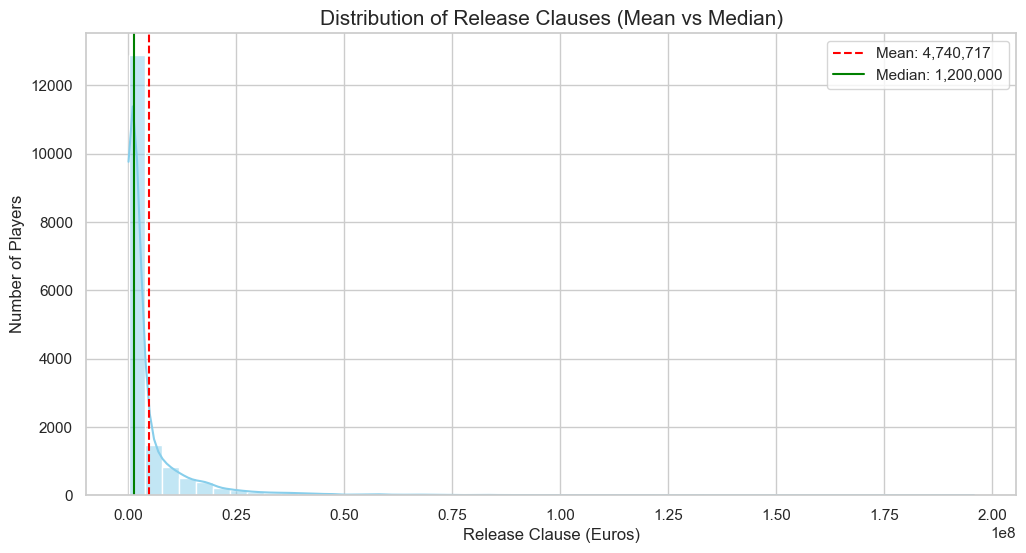

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Set the style
plt.figure(figsize=(12, 6))
sns.set_style("whitegrid")

# 2. Create a Histogram of the Release Clause
# We drop NaNs just for the visualization to see the true distribution
data_to_plot = df['release_clause_eur'].dropna()

sns.histplot(data_to_plot, kde=True, color='skyblue', bins=50)

# 3. Calculate Mean and Median
mean_val = data_to_plot.mean()
median_val = data_to_plot.median()

# 4. Add vertical lines to compare
plt.axvline(mean_val, color='red', linestyle='--', label=f'Mean: {mean_val:,.0f}')
plt.axvline(median_val, color='green', linestyle='-', label=f'Median: {median_val:,.0f}')

# 5. Formatting
plt.title('Distribution of Release Clauses (Mean vs Median)', fontsize=15)
plt.xlabel('Release Clause (Euros)', fontsize=12)
plt.ylabel('Number of Players', fontsize=12)
plt.legend()

plt.show()

In [48]:
# 1. Calculate the median for the release_clause_eur column
median_val = df['release_clause_eur'].median()

# 2. Fill the missing (NaN) values with that median
df['release_clause_eur'] = df['release_clause_eur'].fillna(median_val)

# 3. Verify there are no more missing values
missing_count = df['release_clause_eur'].isnull().sum()

print(f"Median value used for filling: {median_val:,.0f}")
print(f"Remaining missing values in release_clause_eur: {missing_count}")

Median value used for filling: 1,200,000
Remaining missing values in release_clause_eur: 0
